# 06 — Exploratory data analysis

## Objective
Analyze available climate variables at their actual city-month grain. The source does not provide daily observations, relative humidity, AQI, PM2.5, or NDVI, so those variables are not plotted or imputed. The date axis identifies a month, not a daily reading. Correlation is descriptive and does not imply causation.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd().parent if Path.cwd().name.lower()=="notebooks" else Path.cwd()
sys.path.insert(0,str(ROOT/"src"))
from climate_pipeline.config import RAW_DIR, PROJECT_DIR, FINAL_DAILY_COLUMNS
from climate_pipeline import run_pipeline, validate_city_monthly, validate_daily_schema
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns",60)


## Dataset overview and distributions

Review the shape, dates, cities, missingness, and descriptive statistics. Use histograms and boxplots only for measured variables present in the source-derived city-month table.

In [2]:
city_monthly=pd.read_csv(ROOT/"data"/"processed"/"city_monthly.csv",parse_dates=["date"])
print("Shape:",city_monthly.shape,"Cities:",city_monthly.city.nunique())
print("Date range:",city_monthly.date.min().date(),"to",city_monthly.date.max().date())
display(city_monthly.dtypes.to_frame("dtype"))
display(city_monthly[["rainfall_mm","avg_temp_c","max_temp_c","min_temp_c"]].describe().T)
display((100*city_monthly.isna().mean()).round(2).rename("missing_pct").to_frame())


Shape: (2496, 39) Cities: 8
Date range: 2000-01-01 to 2025-12-01


,dtype
city_key,str
city,str
date,datetime64[us]
ALLSKY_SFC_SW_DIFF,float64
ALLSKY_SFC_SW_DNI,float64
ALLSKY_SFC_UV_INDEX,float64
ALLSKY_SRF_ALB,float64
CLOUD_AMT,float64
CLRSKY_SFC_SW_DWN,float64
IMERG_PRECTOT,float64


,count,mean,std,min,25%,50%,75%,max
rainfall_mm,2496.0,3.004506,3.903427,0.000,0.150,1.380000,4.60000,33.590
avg_temp_c,2496.0,25.567145,5.092742,10.466,22.590,25.765000,28.84250,38.205
max_temp_c,2496.0,35.154010,5.534187,20.334,31.070,34.110444,38.87125,48.675
min_temp_c,2496.0,17.197623,6.375366,-1.095,12.605,18.530000,22.69000,30.255


,missing_pct
city_key,0.00
city,0.00
date,0.00
ALLSKY_SFC_SW_DIFF,0.00
ALLSKY_SFC_SW_DNI,3.85
ALLSKY_SFC_UV_INDEX,3.85
ALLSKY_SRF_ALB,3.85
CLOUD_AMT,0.00
CLRSKY_SFC_SW_DWN,0.00
IMERG_PRECTOT,0.00


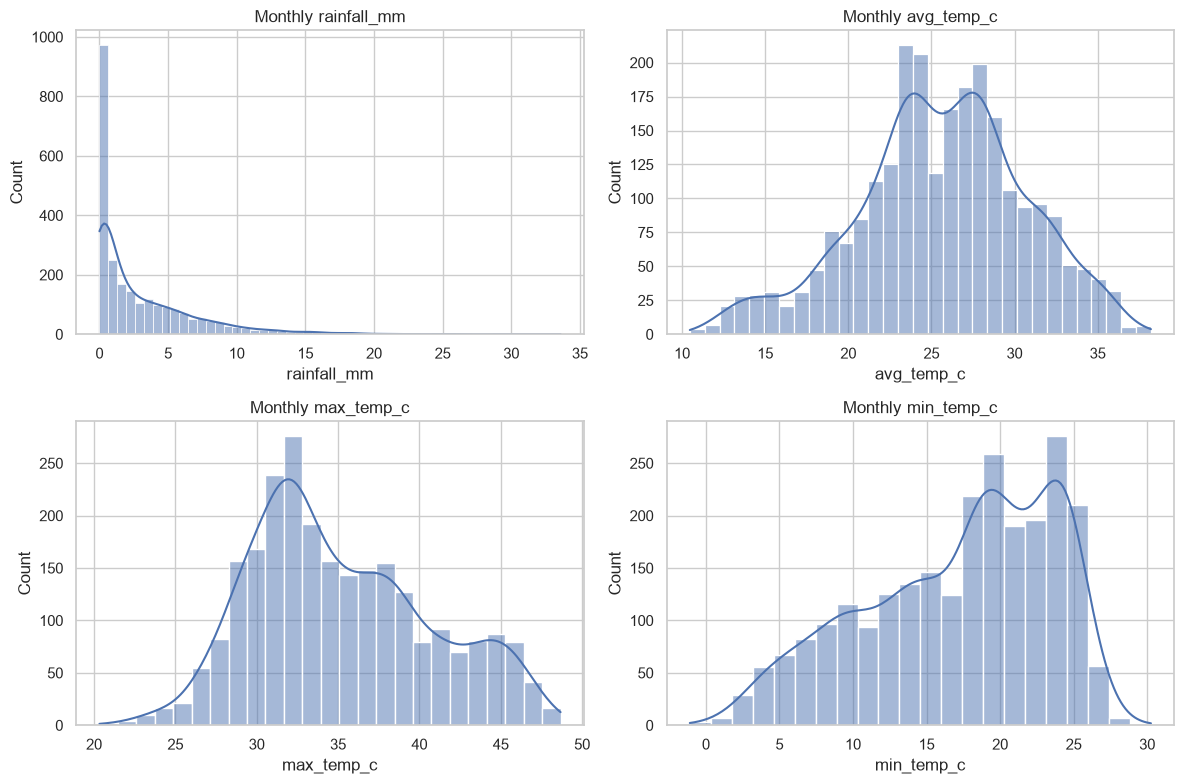

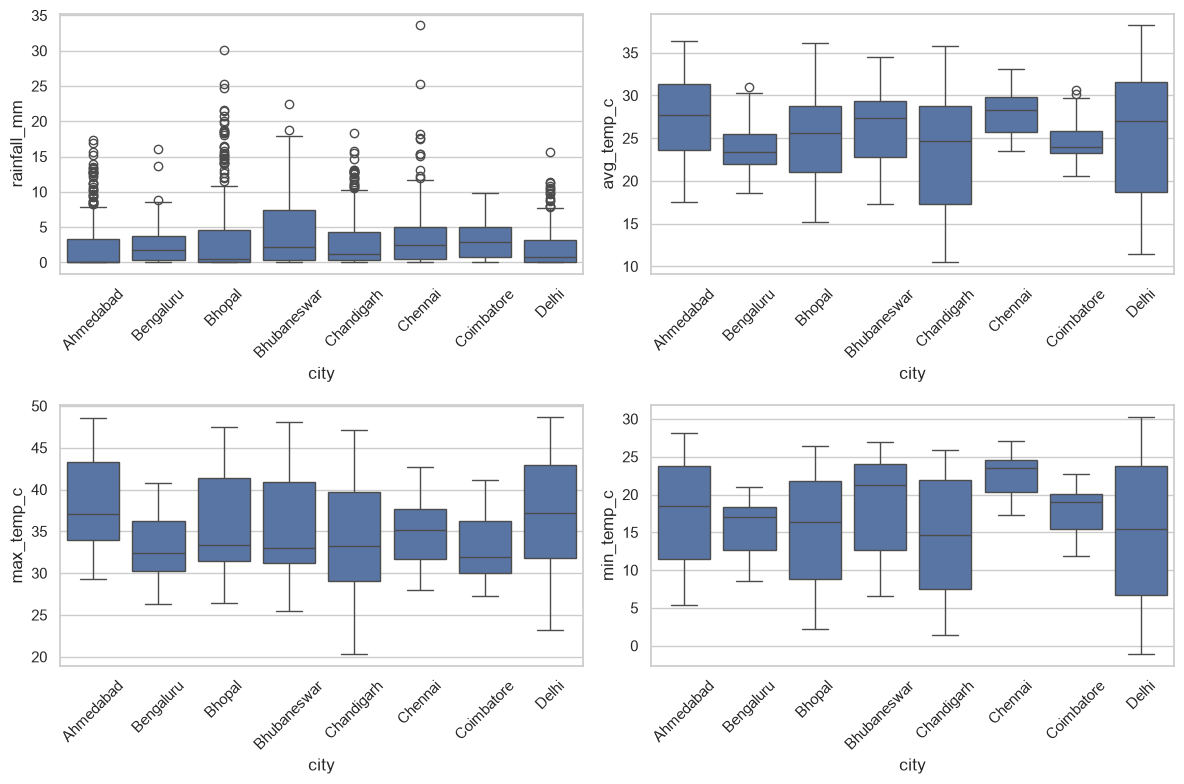

In [3]:
available=["rainfall_mm","avg_temp_c","max_temp_c","min_temp_c"]
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,available): sns.histplot(data=city_monthly,x=col,kde=True,ax=ax); ax.set_title(f"Monthly {col}")
plt.tight_layout()
figure_dir=ROOT/"reports"/"figures"; figure_dir.mkdir(parents=True,exist_ok=True)
fig.savefig(figure_dir/"distribution_histograms.png",dpi=160,bbox_inches="tight")
plt.show()
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,available): sns.boxplot(data=city_monthly,x="city",y=col,ax=ax); ax.tick_params(axis="x",rotation=45)
plt.tight_layout()
fig.savefig(figure_dir/"city_boxplots.png",dpi=160,bbox_inches="tight")
plt.show()


## City comparisons and temporal trends

Compare long-period monthly summary means by city and examine the month-keyed time series. These summaries describe the product's source statistics, not daily extremes or daily totals. Save figures in `reports/figures/` for reproducibility.

,city,state,mean_monthly_temp_c,mean_precipitation_rate_mm_day,mean_monthly_max_c,mean_monthly_min_c
5,Chennai,Tamil Nadu,27.92,3.54,34.85,22.68
0,Ahmedabad,Gujarat,27.51,2.19,38.22,17.64
3,Bhubaneswar,Odisha,26.39,4.18,35.30,18.57
7,Delhi,Delhi (National Capital Territory),25.54,1.99,37.03,15.01
2,Bhopal,Madhya Pradesh,25.43,3.45,35.85,15.49
6,Coimbatore,Tamil Nadu,24.56,3.21,33.03,17.94
1,Bengaluru,Karnataka,23.73,2.42,32.96,15.74
4,Chandigarh,Chandigarh (Union Territory),23.46,3.05,33.99,14.51


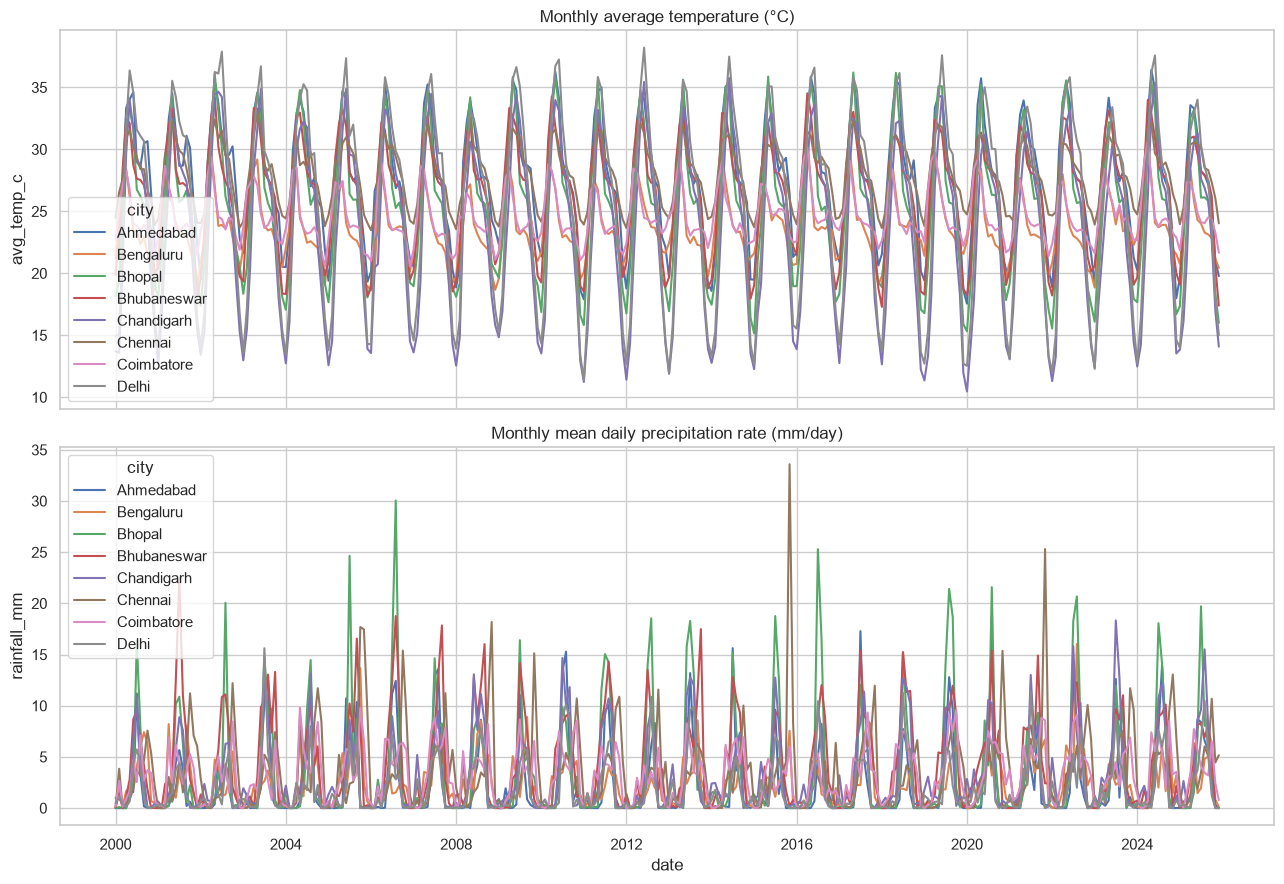

In [4]:
city_summary=city_monthly.groupby(["city","state"],as_index=False).agg(
 mean_monthly_temp_c=("avg_temp_c","mean"),mean_precipitation_rate_mm_day=("rainfall_mm","mean"),
 mean_monthly_max_c=("max_temp_c","mean"),mean_monthly_min_c=("min_temp_c","mean"))
display(city_summary.sort_values("mean_monthly_temp_c",ascending=False).round(2))
fig,axes=plt.subplots(2,1,figsize=(13,9),sharex=True)
sns.lineplot(data=city_monthly,x="date",y="avg_temp_c",hue="city",errorbar=None,ax=axes[0]); axes[0].set_title("Monthly average temperature (°C)")
sns.lineplot(data=city_monthly,x="date",y="rainfall_mm",hue="city",errorbar=None,ax=axes[1]); axes[1].set_title("Monthly mean daily precipitation rate (mm/day)")
plt.tight_layout()
fig.savefig(figure_dir/"monthly_trends.png",dpi=160,bbox_inches="tight")
plt.show()


,rainfall_mm,avg_temp_c,max_temp_c,min_temp_c
rainfall_mm,1.000,0.203,-0.089,0.480
avg_temp_c,0.203,1.000,0.857,0.867
max_temp_c,-0.089,0.857,1.000,0.541
min_temp_c,0.480,0.867,0.541,1.000


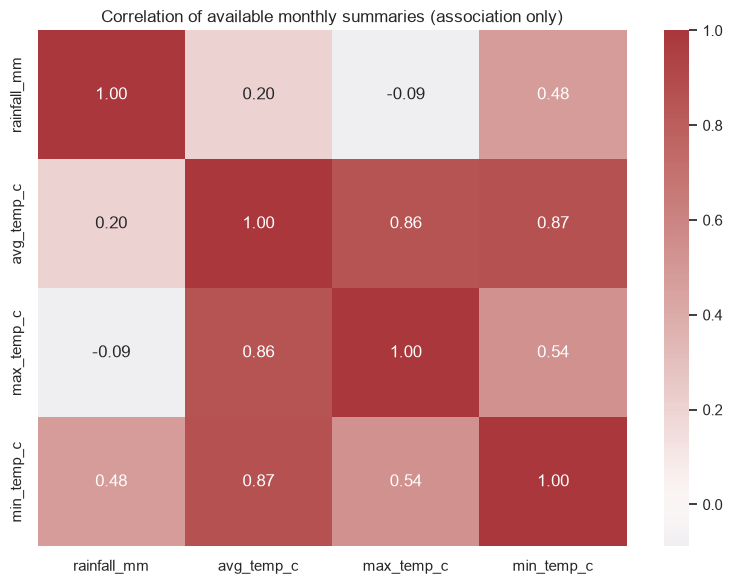

In [5]:
corr=city_monthly[available].corr()
display(corr.round(3))
fig,ax=plt.subplots(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap="vlag",center=0,fmt=".2f",ax=ax)
plt.title("Correlation of available monthly summaries (association only)")
plt.tight_layout()
fig.savefig(figure_dir/"correlation_heatmap.png",dpi=160,bbox_inches="tight")
plt.show()


## EDA conclusion

The EDA supports city comparisons and seasonal/long-term inspection of monthly data. It cannot satisfy the daily climate analysis requirements without daily-resolution source files. Interpret all measured values with the monthly source definitions and units in `reports/data_dictionary.csv`.